In [120]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve, roc_auc_score
from pathlib import Path

from pathlib import Path

print(sys.version)
print(sys.executable)

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
c:\Users\USER\Desktop\credit_scoring_project\.venv312\Scripts\python.exe


In [33]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

In [8]:
project_dir = Path.cwd().parent
data_path = project_dir / "data" / "raw" / "UCI_Credit_Card.csv"
df = pd.read_csv(data_path)
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [12]:
print (df.shape)
print (df.info())
print (df.isna().sum())
print (df.duplicated().sum())

(30000, 25)
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30

всего 30000 клиентов , 25 столбцов , 23 признака  ,ID и целевая переменная (default.payment.next.month)
Пропусков нет
Дубликатов нет 
есть и числовые и категориальные столбцы 

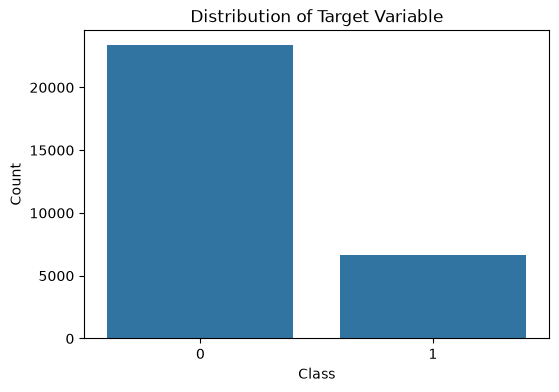

In [15]:
target ='default.payment.next.month'
class_counts = df[target].value_counts()
summary = pd.DataFrame({'Class': class_counts.index, 'Count': class_counts.values})
plt.figure(figsize=(6, 4))
sns.barplot(x='Class', y='Count', data=summary)
plt.title('Distribution of Target Variable')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()


получилось ,что клиентов с дефолтом почти 20 % , а без дефолта 80% 

In [19]:
print(df['ID'].duplicated().sum())
for col in ['SEX', 'EDUCATION', 'MARRIAGE']:
    print(f"Value counts for {col}:")
    print(df[col].value_counts())
    print()

0
Value counts for SEX:
SEX
2    18112
1    11888
Name: count, dtype: int64

Value counts for EDUCATION:
EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64

Value counts for MARRIAGE:
MARRIAGE
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64



In [25]:
display(df.drop(columns=['ID',  target]).describe().T)
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

for cols in pay_cols:
    print(f"{cols}: {sorted(df[cols].unique())}")
    
print(df['ID'].duplicated().sum())    

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


PAY_0: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_2: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_3: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_4: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_5: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_6: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
0


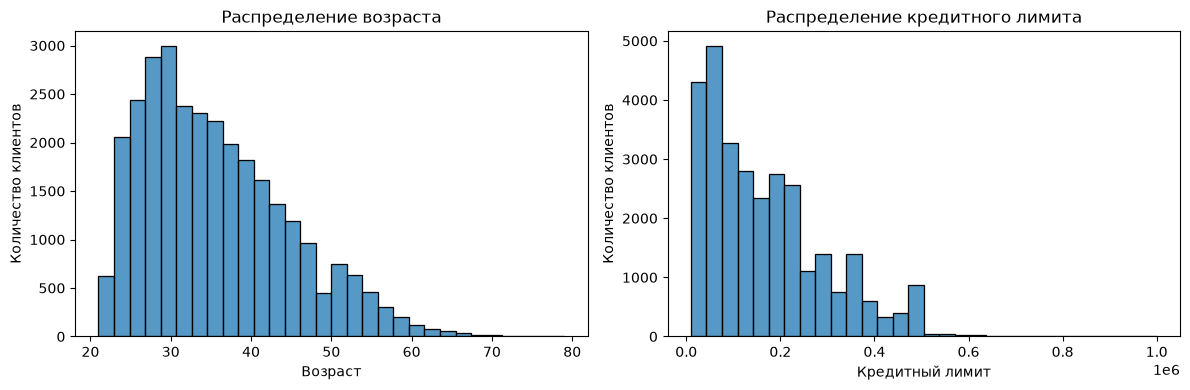

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="AGE", bins=30, ax=axes[0])
axes[0].set_title("Распределение возраста")
axes[0].set_xlabel("Возраст")
axes[0].set_ylabel("Количество клиентов")

sns.histplot(data=df, x="LIMIT_BAL", bins=30, ax=axes[1])
axes[1].set_title("Распределение кредитного лимита")
axes[1].set_xlabel("Кредитный лимит")
axes[1].set_ylabel("Количество клиентов")

plt.tight_layout()
plt.show()

In [35]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df[target])
print(f"Train set shape: {train_df.shape}")
print(f"Test set shape: {test_df.shape}")
print( round(train_df[target].mean(), 4))
print( round(test_df[target].mean(), 4))


Train set shape: (24000, 25)
Test set shape: (6000, 25)
0.2212
0.2212


Было поделено на обучающую и тестовую выборку ,где 24000 клиентов для обучения и 6000 для теста 

,Count,Default_Rate
PAY_0,,
-2,2198,12.69
-1,4527,16.63
0,11781,12.80
1,3000,34.37
2,2138,69.36
3,245,76.73
4,58,65.52
5,18,44.44
6,10,60.00


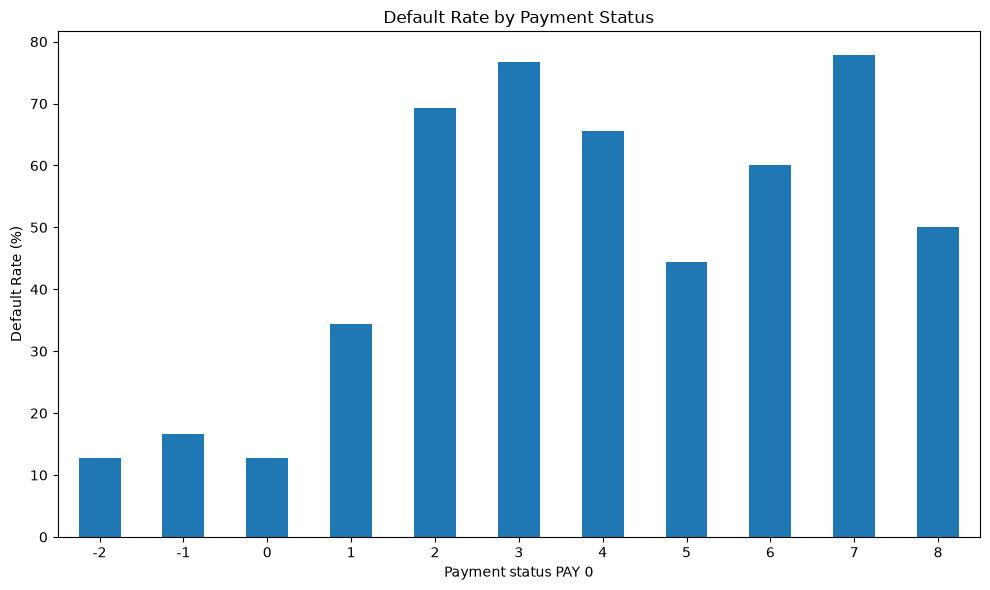

In [45]:
pay_summary = (
    train_df.groupby('PAY_0')[target]
    .agg(['count', 'mean'])
    .rename(columns={'count': 'Count', 'mean': 'Default_Rate'})
)
pay_summary['Default_Rate'] = ((pay_summary['Default_Rate']*100).round(2))
display(pay_summary[['Count', 'Default_Rate']])
pay_summary['Default_Rate'].plot(kind='bar', figsize=(10, 6))


plt.xlabel('Payment status PAY 0')
plt.ylabel('Default Rate (%)')
plt.title('Default Rate by Payment Status')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

pay_0 имеет отличие между группами и несет зачение погашенного кредита.
Статус погашенного кредита заранее составляет примено 15 процентов , просрочен на 1 месяц - почти 40 %, а остальные статусы погашения составили более 40% . 

,count,mean,median
default.payment.next.month,,,
0,18691,178476.91,150000.0
1,5309,128242.61,90000.0


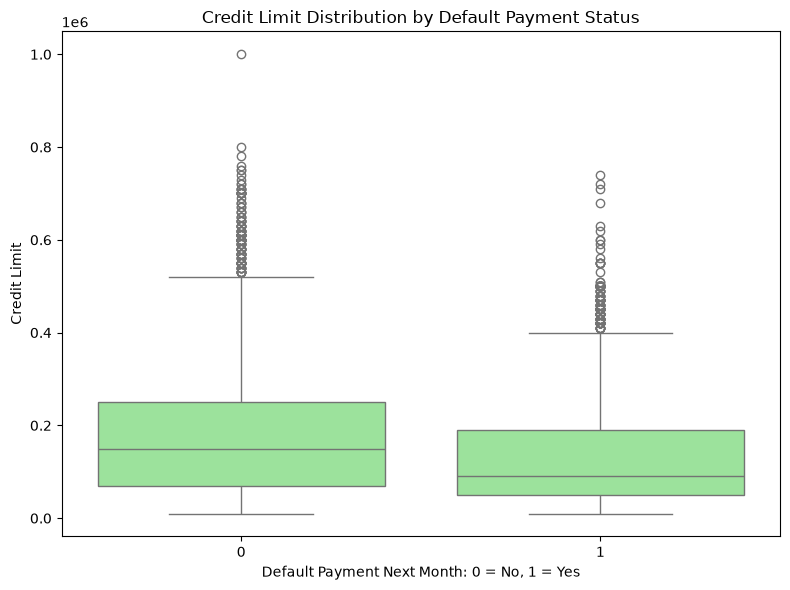

In [48]:
display(
train_df.groupby(target)['LIMIT_BAL']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

plt.figure(figsize=(8, 6))
sns.boxplot(data=train_df, x=target , y='LIMIT_BAL', color = 'lightgreen')

plt.xlabel('Default Payment Next Month: 0 = No, 1 = Yes')
plt.ylabel('Credit Limit') 
plt.title('Credit Limit Distribution by Default Payment Status')
plt.tight_layout()
plt.show()

по графику можно сказать ,Что медиана для статуса "без дефолта" выше, чем у "дефолта". 
без дефолта - 18691 клиент, средний лимит 178 476,91 и медианный лимит 150 000
дефолт - 5309 , средний лимит - 128 242,61 , и медианный лимит 90 000 

In [54]:
df.shape

(30000, 25)

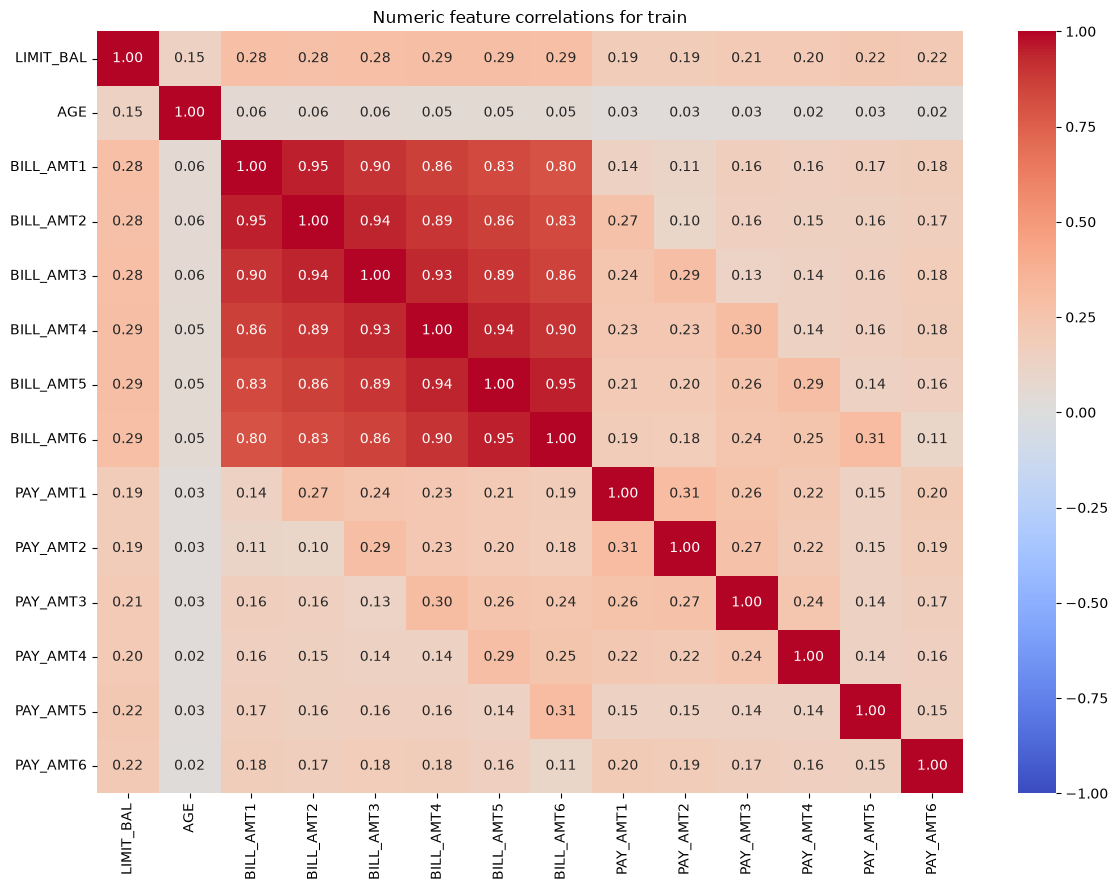

In [52]:
eda_cols = (
    ["LIMIT_BAL", "AGE"]
    +[f"BILL_AMT{i}" for i in range (1, 7)]
    +[f"PAY_AMT{i}" for i in range(1, 7)]

)

corr_matrix = train_df[eda_cols].corr()
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap = 'coolwarm',
    center = 0,
    vmin =-1,
    vmax = 1
)

plt.title("Numeric feature correlations for train")
plt.tight_layout()
plt.show() 

Выводы по ЕДА:

- Датасет содержит 30 000 клиентов и 25 столбцов,
- пропуски или дубликаты не обнаружена, 
- примерно 22% клиентов имеют дефлот,
- данные поделили 80/20 обучение/тестирование, 
- доля дефолтов отличается от pay_0 значительно,
- медиана для дефолта 90 000, без дефлота - 150 000.



Feature Engineering 

In [66]:
def feature_engineering(df):
    result = df.copy()
    
    result['BILL_AMT_SUM'] = result[[f'BILL_AMT{i}' for i in range(1, 7)]].sum(axis=1)
    result['PAY_AMT_SUM'] = result[[f'PAY_AMT{i}' for i in range(1, 7)]].sum(axis=1)
    result['BILL_AMT_MEAN'] = result[[f'BILL_AMT{i}' for i in range(1, 7)]].mean(axis=1)
    result['PAY_AMT_MEAN'] = result[[f'PAY_AMT{i}' for i in range(1, 7)]].mean(axis=1)
    
   
    pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
    result['NUM_DELAYED_PAYMENTS'] = (result[pay_cols] > 0).sum(axis=1)
    limit = result['LIMIT_BAL'].where(result['LIMIT_BAL'] > 0)
    result['BILL_TO_LIMIT_RATIO'] = (result['BILL_AMT_SUM'] / limit)
    return result

In [71]:
train_features = feature_engineering(train_df)
print("До", train_df.shape)
print("После", train_features.shape)


До (24000, 25)
После (24000, 31)


In [68]:
cols_new = ['LIMIT_BAL', 'AGE', 'BILL_AMT_SUM', 'PAY_AMT_SUM', 'BILL_AMT_MEAN', 'PAY_AMT_MEAN', 'NUM_DELAYED_PAYMENTS']
print([col for col in cols_new if col not in train_features.columns])
display(train_features[cols_new].head())

[]


,LIMIT_BAL,AGE,BILL_AMT_SUM,PAY_AMT_SUM,BILL_AMT_MEAN,PAY_AMT_MEAN,NUM_DELAYED_PAYMENTS
22788,160000.0,33,992940.0,39500.0,165490.000000,6583.333333,4
29006,150000.0,34,53.0,53.0,8.833333,8.833333,1
16950,10000.0,50,51461.0,4016.0,8576.833333,669.333333,2
22280,220000.0,29,1117574.0,41687.0,186262.333333,6947.833333,0
11346,310000.0,32,182.0,1526.0,30.333333,254.333333,1


In [72]:
test_features = feature_engineering(test_df)
print(train_features.shape, test_features.shape)

(24000, 31) (6000, 31)


In [75]:
target = 'default.payment.next.month'
X_train = train_features.drop(columns=['ID', target])
y_train = train_features[target]
X_test = test_features.drop(columns=['ID', target])
y_test = test_features[target]

print (X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(24000, 29) (24000,) (6000, 29) (6000,)


In [76]:
categorical_features = ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
numeric_features = [col for col in X_train.columns if col not in categorical_features]  
print("Categorical features:", len(categorical_features))
print("Numeric features:", len(numeric_features))

Categorical features: 9
Numeric features: 20


In [78]:
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), 
    ('scaler', StandardScaler())
])


In [81]:
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),   
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [83]:
preprocessor = ColumnTransformer(
    transformers=[  
        ('num', numeric_pipeline, numeric_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

In [85]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

In [88]:
model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


совершим кросс валидацию для проверки качества моделей 

In [101]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(
    model, 
    X_train,
    y_train,
    cv=cv,
    scoring=['roc_auc', 'precision', 'recall', 'f1'],
    error_score='raise'
    )

for metric in ['roc_auc', 'precision', 'recall', 'f1']:
    print(f"Mean {metric}: {cv_results['test_score'].mean():.4f}")

Mean roc_auc: 0.7698
Mean precision: 0.7698
Mean recall: 0.7698
Mean f1: 0.7698


In [103]:
print(scores['test_roc_auc'].mean())
print(scores['test_precision'].mean())
print(scores['test_recall'].mean())
print(scores['test_f1'].mean())

0.769752526412432
0.6791789937647179
0.3563780749071249
0.4672462892333747


Метрики на кросс-валидации выведены на 5 разбиениях:
roc-auc: 0,77 
Precision: 0.679
Recall: 0.356
F1: 0.467

модель способна обнаружить примерно 36 % реальных дефлотов 
примерно 68% предупреждений о дефолтах верны

Сравним несколько настроек логрега с greadsearchCV 

In [109]:
params = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__class_weight': ['balanced', None],
}

search = GridSearchCV(
    estimator=model,
    param_grid=params,
    scoring= ['roc_auc', 'precision', 'recall', 'f1'],

    cv=cv,
    refit='roc_auc',
    n_jobs=-1,
    verbose=1,
    error_score='raise'
)   
search.fit(X_train, y_train)

print("Best parameters found: ", search.best_params_)
print("Best ROC AUC score: ", search.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters found:  {'classifier__C': 0.01, 'classifier__class_weight': None}
Best ROC AUC score:  0.7709828329528534


In [110]:
results_df = pd.DataFrame(search.cv_results_)
columns_to_display = ['param_classifier__C', 'param_classifier__class_weight', 'mean_test_roc_auc', 'mean_test_precision', 'mean_test_recall', 'mean_test_f1']
display(results_df[columns_to_display].sort_values(by='mean_test_roc_auc', ascending=False))

,param_classifier__C,param_classifier__class_weight,mean_test_roc_auc,mean_test_precision,mean_test_recall,mean_test_f1
1,0.01,NaN,0.770983,0.675393,0.333589,0.446410
0,0.01,balanced,0.770804,0.501111,0.576758,0.536272
2,0.10,balanced,0.770780,0.496901,0.578454,0.534574
4,1.00,balanced,0.770492,0.493607,0.578266,0.532579
3,0.10,NaN,0.770386,0.677509,0.357319,0.467739
6,10.00,balanced,0.770077,0.492900,0.578454,0.532249
5,1.00,NaN,0.769753,0.679179,0.356378,0.467246
7,10.00,NaN,0.769527,0.678477,0.356001,0.466782


In [112]:
best_model = search.best_estimator_

In [114]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)[:, 1]

print("ROC AUC Score:", roc_auc_score(y_test, y_pred_proba))
print("Precision Score:", precision_score(y_test, y_pred))
print("Recall Score:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))


ROC AUC Score: 0.7607287515334045
Precision Score: 0.6574344023323615
Recall Score: 0.3398643556895252
F1 Score: 0.44808743169398907


модель обнаруживает 34 из 100 дефлота , из предупреждений 66 % верные 

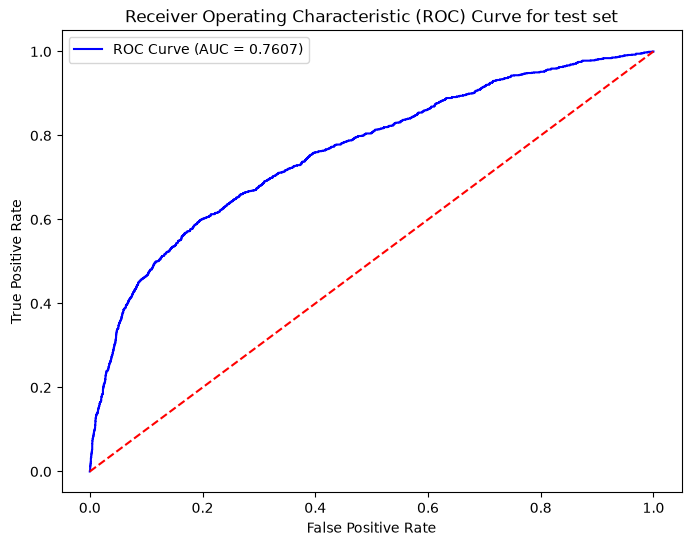

In [119]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
auc_score = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.4f})', color='blue')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.title('Receiver Operating Characteristic (ROC) Curve for test set')      
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()


project_root = Path.cwd().parent
if project_root.name == "notebooks":
    project_root = project_root.parent
reports_dir = project_root / "reports" / "figures"
reports_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(reports_dir / "roc_curve.png", dpi=300, bbox_inches='tight')


plt.show()  

Roc- кривая модели на тесте проходит выше диагонали классификатора , имя значение 0,7607 ,что  может быть свидетельством ,Что модель различает клиентов с дефолтом и без него . Кривая показывает соотношение доли дефолтов и доли ложных срабатываний при изменении порога классификации. 

In [122]:
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
reports_dir = project_root / "reports" / "figures"
reports_dir.mkdir(parents=True, exist_ok=True)

metrics = {
    "roc_auc": roc_auc_score(y_test, y_pred_proba),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred)
}
with open(reports_dir / "metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)
    
pd.DataFrame(search.cv_results_).to_csv(reports_dir / "grid_search_results.csv", index=False)
print(f"Metrics saved to {reports_dir}")

Metrics saved to c:\Users\USER\Desktop\credit_scoring_project\reports\figures
